In [74]:
import os
import random
import time

import cv2
import numpy as np
from PIL import Image

import torch
import torch.backends.cudnn as cudnn
import torch.nn as nn
import torch.nn.functional as F
import torch.optim
from torch.utils import data

!pip install yacs tensorboardX 

In [75]:
from yacs.config import CfgNode as CN

_C = CN()

# Set this to False for local CPU training.
_C.USE_CUDA = True
_C.OUTPUT_DIR = 'model'
_C.LOG_DIR = 'training_log'
_C.GPUS = (0,)
_C.WORKERS = 0
_C.PRINT_FREQ = 10
_C.AUTO_RESUME = False
_C.PIN_MEMORY = True

# cuDNN settings
_C.CUDNN = CN()
_C.CUDNN.BENCHMARK = True
_C.CUDNN.DETERMINISTIC = False
_C.CUDNN.ENABLED = True

# Model settings
_C.MODEL = CN()
_C.MODEL.NAME = 'pidnet_s'
_C.MODEL.PRETRAINED = (
    'pretrained_models'
    'imagenet/PIDNet_S_ImageNet.pth.tar'
)
_C.MODEL.ALIGN_CORNERS = True
_C.MODEL.NUM_OUTPUTS = 2

# Loss settings
_C.LOSS = CN()
_C.LOSS.USE_OHEM = True
_C.LOSS.OHEMTHRES = 0.9
_C.LOSS.OHEMKEEP = 131072
_C.LOSS.CLASS_BALANCE = False
_C.LOSS.BALANCE_WEIGHTS = [0.4, 1.0]
_C.LOSS.SB_WEIGHTS = 1.0

# Dataset settings
_C.DATASET = CN()
_C.DATASET.DATASET = 'camvid'
_C.DATASET.NUM_CLASSES = 11
_C.DATASET.ROOT = 'data/'
_C.DATASET.TRAIN_SET = '/list/camvid/trainval.lst'
_C.DATASET.TEST_SET = '/list/camvid/val.lst'

# Training settings. The full CamVid resolution fits a 16 GB T4 at batch 4
# for PIDNet-S; CPU mode below overrides the batch size and workers.
_C.TRAIN = CN()
_C.TRAIN.IMAGE_SIZE = [960, 720]  # width, height
_C.TRAIN.BASE_SIZE = 960
_C.TRAIN.FLIP = True
_C.TRAIN.MULTI_SCALE = True
_C.TRAIN.SCALE_FACTOR = 16
_C.TRAIN.LR = 0.005
_C.TRAIN.EXTRA_LR = 0.0005
_C.TRAIN.OPTIMIZER = 'sgd'
_C.TRAIN.MOMENTUM = 0.9
_C.TRAIN.WD = 0.0005
_C.TRAIN.NESTEROV = False
_C.TRAIN.IGNORE_LABEL = 255
_C.TRAIN.BEGIN_EPOCH = 0
_C.TRAIN.END_EPOCH = 200
_C.TRAIN.RESUME = False
_C.TRAIN.BATCH_SIZE_PER_GPU = 4
_C.TRAIN.SHUFFLE = True

# Testing settings
_C.TEST = CN()
_C.TEST.IMAGE_SIZE = [960, 720]  # width, height
_C.TEST.BASE_SIZE = 960
_C.TEST.BATCH_SIZE_PER_GPU = 1
_C.TEST.MODEL_FILE = ''
_C.TEST.FLIP_TEST = False
_C.TEST.MULTI_SCALE = False
_C.TEST.OUTPUT_INDEX = 1

config = _C.clone()
config.freeze()

use_cuda = config.USE_CUDA and torch.cuda.is_available()
device = torch.device('cuda' if use_cuda else 'cpu')
print(f'Training device: {device}')
print(config)

Training device: cuda
AUTO_RESUME: False
CUDNN:
  BENCHMARK: True
  DETERMINISTIC: False
  ENABLED: True
DATASET:
  DATASET: camvid
  NUM_CLASSES: 11
  ROOT: data/
  TEST_SET: /list/camvid/val.lst
  TRAIN_SET: /list/camvid/trainval.lst
GPUS: (0,)
LOG_DIR: training_log
LOSS:
  BALANCE_WEIGHTS: [0.4, 1.0]
  CLASS_BALANCE: False
  OHEMKEEP: 131072
  OHEMTHRES: 0.9
  SB_WEIGHTS: 1.0
  USE_OHEM: True
MODEL:
  ALIGN_CORNERS: True
  NAME: pidnet_s
  NUM_OUTPUTS: 2
  PRETRAINED: pretrained_modelsimagenet/PIDNet_S_ImageNet.pth.tar
OUTPUT_DIR: model
PIN_MEMORY: True
PRINT_FREQ: 10
TEST:
  BASE_SIZE: 960
  BATCH_SIZE_PER_GPU: 1
  FLIP_TEST: False
  IMAGE_SIZE: [960, 720]
  MODEL_FILE: 
  MULTI_SCALE: False
  OUTPUT_INDEX: 1
TRAIN:
  BASE_SIZE: 960
  BATCH_SIZE_PER_GPU: 4
  BEGIN_EPOCH: 0
  END_EPOCH: 200
  EXTRA_LR: 0.0005
  FLIP: True
  IGNORE_LABEL: 255
  IMAGE_SIZE: [960, 720]
  LR: 0.005
  MOMENTUM: 0.9
  MULTI_SCALE: True
  NESTEROV: False
  OPTIMIZER: sgd
  RESUME: False
  SCALE_FACTOR: 16


### Dataset creation

In [76]:
### Base Image Dataset, with transformations
y_k_size = 6
x_k_size = 6

class BaseDataset(data.Dataset):
    def __init__(self,
                 ignore_label=255,
                 base_size=2048,
                 crop_size=(512, 1024),
                 scale_factor=16,
                 mean=[0.485, 0.456, 0.406],
                 std=[0.229, 0.224, 0.225]):
        self.base_size = base_size
        self.crop_size = crop_size
        self.ignore_label = ignore_label
        self.mean = mean
        self.std = std
        self.scale_factor = scale_factor
        self.files = []

    def __len__(self):
        return len(self.files)

    def input_transform(self, image, city=True):
        if city:
            image = image.astype(np.float32)[:, :, ::-1]
        else:
            image = image.astype(np.float32)
        image = image / 255.0
        image -= self.mean
        image /= self.std
        return image

    def label_transform(self, label):
        return np.array(label).astype(np.int64)

    def pad_image(self, image, h, w, size, padvalue):
        pad_image = image.copy()
        pad_h = max(size[0] - h, 0)
        pad_w = max(size[1] - w, 0)
        if pad_h > 0 or pad_w > 0:
            pad_image = cv2.copyMakeBorder(image, 0, pad_h, 0, pad_w,
                                           cv2.BORDER_CONSTANT, value=padvalue)
        return pad_image

    def rand_crop(self, image, label, edge):
        h, w = image.shape[:-1]
        image = self.pad_image(image, h, w, self.crop_size, (0.0, 0.0, 0.0))
        label = self.pad_image(label, h, w, self.crop_size, (self.ignore_label,))
        edge = self.pad_image(edge, h, w, self.crop_size, (0.0,))
        new_h, new_w = label.shape
        x = random.randint(0, new_w - self.crop_size[1])
        y = random.randint(0, new_h - self.crop_size[0])
        image = image[y:y+self.crop_size[0], x:x+self.crop_size[1]]
        label = label[y:y+self.crop_size[0], x:x+self.crop_size[1]]
        edge = edge[y:y+self.crop_size[0], x:x+self.crop_size[1]]
        return image, label, edge

    def multi_scale_aug(self, image, label=None, edge=None, rand_scale=1, rand_crop=True):
        long_size = int(self.base_size * rand_scale + 0.5)
        h, w = image.shape[:2]
        if h > w:
            new_h = long_size
            new_w = int(w * long_size / h + 0.5)
        else:
            new_w = long_size
            new_h = int(h * long_size / w + 0.5)
        image = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        if label is not None:
            label = cv2.resize(label, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
            if edge is not None:
                edge = cv2.resize(edge, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
        else:
            return image
        if rand_crop:
            image, label, edge = self.rand_crop(image, label, edge)
        return image, label, edge

    def gen_sample(self, image, label, multi_scale=True, is_flip=True, edge_pad=True, edge_size=4, city=True):
        edge_label = np.clip(label, 0, 255).astype(np.uint8)
        edge = cv2.Canny(edge_label, 0.1, 0.2)
        kernel = np.ones((edge_size, edge_size), np.uint8)
        if edge_pad:
            edge = edge[y_k_size:-y_k_size, x_k_size:-x_k_size]
            edge = np.pad(edge, ((y_k_size,y_k_size),(x_k_size,x_k_size)), mode='constant')
        edge = (cv2.dilate(edge, kernel, iterations=1)>50)*1.0
        if multi_scale:
            rand_scale = 0.5 + random.randint(0, self.scale_factor) / 10.0
            image, label, edge = self.multi_scale_aug(image, label, edge, rand_scale=rand_scale)
        image = self.input_transform(image, city=city)
        label = self.label_transform(label)
        image = image.transpose((2, 0, 1))
        if is_flip:
            flip = np.random.choice(2) * 2 - 1
            image = image[:, :, ::flip]
            label = label[:, ::flip]
            edge = edge[:, ::flip]
        return image, label, edge

    def inference(self, config, model, image):
        size = image.size()
        pred = model(image)
        if config.MODEL.NUM_OUTPUTS > 1:
            pred = pred[config.TEST.OUTPUT_INDEX]
        pred = F.interpolate(input=pred, size=size[-2:], mode='bilinear', align_corners=config.MODEL.ALIGN_CORNERS)
        return pred.exp()

In [77]:

class Cityscapes(BaseDataset):
    def __init__(self, 
                 root, 
                 list_path,
                 image_root,
                 gt_root,
                 num_classes=19,
                 multi_scale=True, 
                 flip=True, 
                 ignore_label=255, 
                 base_size=2048, 
                 crop_size=(512, 1024),
                 scale_factor=16, 
                 mean=[0.485, 0.456, 0.406], 
                 std=[0.229, 0.224, 0.225],
                 bd_dilate_size=4):

        super(Cityscapes, self).__init__(ignore_label, base_size,
                crop_size, scale_factor, mean, std,)

        self.root = root
        self.list_path = list_path
        self.image_root = image_root
        self.gt_root = gt_root
        self.num_classes = num_classes

        self.multi_scale = multi_scale
        self.flip = flip
        
        self.img_list = [line.strip().split() for line in open(os.path.join(root, list_path))]

        self.files = self.read_files()

        self.label_mapping = {-1: ignore_label, 0: ignore_label, 
                              1: ignore_label, 2: ignore_label, 
                              3: ignore_label, 4: ignore_label, 
                              5: ignore_label, 6: ignore_label, 
                              7: 0, 8: 1, 9: ignore_label, 
                              10: ignore_label, 11: 2, 12: 3, 
                              13: 4, 14: ignore_label, 15: ignore_label, 
                              16: ignore_label, 17: 5, 18: ignore_label, 
                              19: 6, 20: 7, 21: 8, 22: 9, 23: 10, 24: 11,
                              25: 12, 26: 13, 27: 14, 28: 15, 
                              29: ignore_label, 30: ignore_label, 
                              31: 16, 32: 17, 33: 18}
        self.class_weights = torch.FloatTensor([0.8373, 0.918, 0.866, 1.0345, 
                                        1.0166, 0.9969, 0.9754, 1.0489,
                                        0.8786, 1.0023, 0.9539, 0.9843, 
                                        1.1116, 0.9037, 1.0865, 1.0955, 
                                        1.0865, 1.1529, 1.0507]).cuda()
        
        self.bd_dilate_size = bd_dilate_size
    
    def read_files(self):
        files = []
        if 'test' in self.list_path:
            for item in self.img_list:
                image_path = item
                name = os.path.splitext(os.path.basename(image_path[0]))[0]
                files.append({
                    "img": image_path[0],
                    "name": name,
                })
        else:
            for item in self.img_list:
                image_path, label_path = item
                name = os.path.splitext(os.path.basename(label_path))[0]
                files.append({
                    "img": image_path,
                    "label": label_path,
                    "name": name
                })
        return files
        
    def convert_label(self, label, inverse=False):
        label = label.astype(np.int64, copy=True)
        temp = label.copy()
        if inverse:
            for v, k in self.label_mapping.items():
                label[temp == k] = v
        else:
            for k, v in self.label_mapping.items():
                label[temp == k] = v
        return label

    def __getitem__(self, index):
        item = self.files[index]
        name = item["name"]
        image = cv2.imread(
            os.path.join(self.image_root, item["img"]),
            cv2.IMREAD_COLOR
        )

        size = image.shape

        if 'test' in self.list_path:
            image = self.input_transform(image)
            image = image.transpose((2, 0, 1))

            return image.copy(), np.array(size), name

        label = cv2.imread(
            os.path.join(self.gt_root, item["label"]),
            cv2.IMREAD_GRAYSCALE
        )
        label = self.convert_label(label)

        image, label, edge = self.gen_sample(image, label, 
                                self.multi_scale, self.flip, edge_size=self.bd_dilate_size)

        return image.copy(), label.copy(), edge.copy(), np.array(size), name

    
    def single_scale_inference(self, config, model, image):
        pred = self.inference(config, model, image)
        return pred




    def save_pred(self, preds, sv_path, name):
        preds = np.asarray(np.argmax(preds.cpu(), axis=1), dtype=np.uint8)
        for i in range(preds.shape[0]):
            pred = self.convert_label(preds[i], inverse=True)
            save_img = Image.fromarray(pred)
            save_img.save(os.path.join(sv_path, name[i]+'.png'))

In [78]:
class CamVid(BaseDataset):
    def __init__(self, 
                 root, 
                 list_path, 
                 num_classes=11,
                 multi_scale=True, 
                 flip=True, 
                 ignore_label=255, 
                 base_size=960, 
                 crop_size=(720, 960),
                 scale_factor=16,
                 mean=[0.485, 0.456, 0.406], 
                 std=[0.229, 0.224, 0.225],
                 bd_dilate_size=4):

        super(CamVid, self).__init__(ignore_label, base_size,
                crop_size, scale_factor, mean, std)

        self.root = root
        self.list_path = list_path
        self.num_classes = num_classes

        self.multi_scale = multi_scale
        self.flip = flip
        
        self.img_list = [line.strip().split() for line in open(root+list_path)]

        self.files = self.read_files()


        self.ignore_label = ignore_label
        
        self.color_list = [[0, 128, 192], [128, 0, 0], [64, 0, 128],
                             [192, 192, 128], [64, 64, 128], [64, 64, 0],
                             [128, 64, 128], [0, 0, 192], [192, 128, 128],
                             [128, 128, 128], [128, 128, 0]]
        
        self.class_weights = None
        
        self.bd_dilate_size = bd_dilate_size
    
    def read_files(self):
        files = []

        for item in self.img_list:
            image_path, label_path = item
            name = os.path.splitext(os.path.basename(label_path))[0]
            files.append({
                "img": image_path,
                "label": label_path,
                "name": name
            })
            
        return files
        
    def color2label(self, color_map):
        label = np.ones(color_map.shape[:2])*self.ignore_label
        for i, v in enumerate(self.color_list):
            label[(color_map == v).sum(2)==3] = i

        return label.astype(np.uint8)
    
    def label2color(self, label):
        color_map = np.zeros(label.shape+(3,))
        for i, v in enumerate(self.color_list):
            color_map[label==i] = self.color_list[i]
            
        return color_map.astype(np.uint8)

    def __getitem__(self, index):
        item = self.files[index]
        name = item["name"]
        image = Image.open(os.path.join(self.root,'camvid',item["img"])).convert('RGB')
        image = np.array(image)
        size = image.shape

        color_map = Image.open(os.path.join(self.root,'camvid',item["label"])).convert('RGB')
        color_map = np.array(color_map)
        label = self.color2label(color_map)

        image, label, edge = self.gen_sample(image, label, 
                                self.multi_scale, self.flip, edge_pad=False,
                                edge_size=self.bd_dilate_size, city=False)

        return image.copy(), label.copy(), edge.copy(), np.array(size), name

    def single_scale_inference(self, config, model, image):
        pred = self.inference(config, model, image)
        return pred

    def save_pred(self, preds, sv_path, name):
        preds = np.asarray(np.argmax(preds.cpu(), axis=1), dtype=np.uint8)
        for i in range(preds.shape[0]):
            pred = self.label2color(preds[i])
            save_img = Image.fromarray(pred)
            save_img.save(os.path.join(sv_path, name[i]+'.png'))

        
        

### Model Building Blocks

In [79]:
BatchNorm2d = nn.BatchNorm2d
bn_mom = 0.1            # momentum for batch normalization
algc = False

In [80]:
# ResNet basic block - used as a skip connection
class BasicBlock(nn.Module):
    expansion = 1           # multiplier that says how many channels are produced

    def __init__(self, inplanes, planes, stride=1, downsample=None, no_relu=False):
        super(BasicBlock, self).__init__()

        # First conv layer
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=3, stride=stride,
                               padding=1, bias=False)
        self.bn1 = BatchNorm2d(planes, momentum=bn_mom)
        self.relu = nn.ReLU(inplace=True)

        # Second conv layer 
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3,
                               padding=1, bias=False)
        self.bn2 = BatchNorm2d(planes, momentum=bn_mom)

        self.downsample = downsample
        self.stride = stride
        self.no_relu = no_relu

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            residual = self.downsample(x)

        out += residual         # model learns output + x , thus introducing a skip connection -> good for segmentation

        if self.no_relu:
            return out
        else:
            return self.relu(out)

In [81]:
# The bottleneck layer - it is more efficient when we want depth and width without cost increase
# It squeezes the image then does processing with a higher kernel then expands it again
class Bottleneck(nn.Module):
    expansion = 2

    def __init__(self, inplanes, planes, stride=1, downsample=None, no_relu=True):
        super(Bottleneck, self).__init__()
        # First Conv layer (1x1 convolution - it computes a weighted sum of pixels across channels)
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=1, bias=False)
        self.bn1 = BatchNorm2d(planes, momentum=bn_mom)

        # Second Conv layer with relu (3x3 convolution)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=stride,
                               padding=1, bias=False)
        self.bn2 = BatchNorm2d(planes, momentum=bn_mom)
        self.relu = nn.ReLU(inplace=True)

        # Third conv layer with a relu (1x1 convolution)
        self.conv3 = nn.Conv2d(planes, planes * self.expansion, kernel_size=1,
                               bias=False)
        self.bn3 = BatchNorm2d(planes * self.expansion, momentum=bn_mom)


        self.downsample = downsample
        self.stride = stride
        self.no_relu = no_relu

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            residual = self.downsample(x)

        out += residual
        if self.no_relu:
            return out
        else:
            return self.relu(out)

In [82]:
class SegmentHead(nn.Module):

    def __init__(self, inplanes, interplanes, outplanes, scale_factor=None):
        super(SegmentHead, self).__init__()
        # Layer 1 (+ RELU)
        self.bn1 = BatchNorm2d(inplanes, momentum=bn_mom)
        self.conv1 = nn.Conv2d(inplanes, interplanes, kernel_size=3, padding=1, bias=False)

        # Layer 2 (+ RELU)
        self.bn2 = BatchNorm2d(interplanes, momentum=bn_mom)
        self.conv2 = nn.Conv2d(interplanes, outplanes, kernel_size=1, padding=0, bias=True)

        self.relu = nn.ReLU(inplace=True)

        self.scale_factor = scale_factor

    def forward(self, x):
        
        x = self.conv1(self.relu(self.bn1(x)))
        out = self.conv2(self.relu(self.bn2(x)))

        if self.scale_factor is not None:
            height = x.shape[-2] * self.scale_factor
            width = x.shape[-1] * self.scale_factor
            out = F.interpolate(out,
                        size=[height, width],
                        mode='bilinear', align_corners=algc)

        return out

##### For smaller networks, PAPPM and Light_Bag is used

In [83]:
# Pyramid Pooling Module (PPM) - Fast Aggregation of Contexts
# This is a parallel architecture which can be used in the smaller PIDNets and is faster to train
class PAPPM(nn.Module):
    def __init__(self, inplanes, branch_planes, outplanes, BatchNorm=nn.BatchNorm2d):
        super(PAPPM, self).__init__()
        bn_mom = 0.1
        # 5x2 average pool 
        self.scale1 = nn.Sequential(nn.AvgPool2d(kernel_size=5, stride=2, padding=2),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # 9x4 average pool 
        self.scale2 = nn.Sequential(nn.AvgPool2d(kernel_size=9, stride=4, padding=4),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # 17x8 average pool
        self.scale3 = nn.Sequential(nn.AvgPool2d(kernel_size=17, stride=8, padding=8),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # Gloabl Average Pool
        self.scale4 = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # 1x1 conv (skip connection)
        self.scale0 = nn.Sequential(
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # will need to decipher later 
        self.scale_process = nn.Sequential(
                                    BatchNorm(branch_planes*4, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(branch_planes*4, branch_planes*4, kernel_size=3, padding=1, groups=4, bias=False),
                                    )

      
        self.compression = nn.Sequential(
                                    BatchNorm(branch_planes * 5, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(branch_planes * 5, outplanes, kernel_size=1, bias=False),
                                    )
        
        self.shortcut = nn.Sequential(
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, outplanes, kernel_size=1, bias=False),
                                    )


    def forward(self, x):
        width = x.shape[-1]
        height = x.shape[-2]        
        scale_list = []

        x_ = self.scale0(x)
        scale_list.append(F.interpolate(self.scale1(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        scale_list.append(F.interpolate(self.scale2(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        scale_list.append(F.interpolate(self.scale3(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        scale_list.append(F.interpolate(self.scale4(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        
        scale_out = self.scale_process(torch.cat(scale_list, 1))
       
        out = self.compression(torch.cat([x_,scale_out], 1)) + self.shortcut(x)
        return out

In [84]:
# Combination of p,i,d barnches 
class Light_Bag(nn.Module):
    def __init__(self, in_channels, out_channels, BatchNorm=nn.BatchNorm2d):
        super(Light_Bag, self).__init__()
        self.conv_p = nn.Sequential(
                                nn.Conv2d(in_channels, out_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(out_channels)
                                )
        self.conv_i = nn.Sequential(
                                nn.Conv2d(in_channels, out_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(out_channels)
                                )
        
    def forward(self, p, i, d):
        edge_att = torch.sigmoid(d)
        
        p_add = self.conv_p((1-edge_att)*i + p)
        i_add = self.conv_i(i + edge_att*p)
        
        return p_add + i_add
    

In [85]:
# This is for learning high level semantics selectively 
# Takes in input from I channel to supply to P channel 

class PagFM(nn.Module):
    def __init__(self, in_channels, mid_channels, after_relu=False, with_channel=False, BatchNorm=nn.BatchNorm2d):
        super(PagFM, self).__init__()
        self.with_channel = with_channel
        self.after_relu = after_relu
        self.f_x = nn.Sequential(
                                nn.Conv2d(in_channels, mid_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(mid_channels)
                                )
        self.f_y = nn.Sequential(
                                nn.Conv2d(in_channels, mid_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(mid_channels)
                                )
        if with_channel:
            self.up = nn.Sequential(
                                    nn.Conv2d(mid_channels, in_channels, 
                                              kernel_size=1, bias=False),
                                    BatchNorm(in_channels)
                                   )
        if after_relu:
            self.relu = nn.ReLU(inplace=True)
        
    def forward(self, x, y):
        input_size = x.size()
        if self.after_relu:
            y = self.relu(y)
            x = self.relu(x)
        
        y_q = self.f_y(y)
        y_q = F.interpolate(y_q, size=[input_size[2], input_size[3]],
                            mode='bilinear', align_corners=False)
        x_k = self.f_x(x)
        
        if self.with_channel:
            sim_map = torch.sigmoid(self.up(x_k * y_q))
        else:
            sim_map = torch.sigmoid(torch.sum(x_k * y_q, dim=1).unsqueeze(1))
        
        y = F.interpolate(y, size=[input_size[2], input_size[3]],
                            mode='bilinear', align_corners=False)
        x = (1-sim_map)*x + sim_map*y
        
        return x

### Combined Network

In [ ]:
class PIDNet(nn.Module):
    def __init__(self, m=2, n=3, num_classes=19, planes=64, ppm_planes=96, head_planes=128, augment=True):
        super(PIDNet, self).__init__()
        self.augment = augment

                
        # I Branch - Central Branch 
        self.conv1 =  nn.Sequential(
                          nn.Conv2d(3,planes,kernel_size=3, stride=2, padding=1),       
                          BatchNorm2d(planes, momentum=bn_mom),
                          nn.ReLU(inplace=True), 

                          nn.Conv2d(planes,planes,kernel_size=3, stride=2, padding=1),
                          BatchNorm2d(planes, momentum=bn_mom),
                          nn.ReLU(inplace=True),
                      )
        
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = self._make_layer(BasicBlock, planes, planes, m)
        self.layer2 = self._make_layer(BasicBlock, planes, planes * 2, m, stride=2)
        self.layer3 = self._make_layer(BasicBlock, planes * 2, planes * 4, n, stride=2)
        self.layer4 = self._make_layer(BasicBlock, planes * 4, planes * 8, n, stride=2)
        self.layer5 =  self._make_layer(Bottleneck, planes * 8, planes * 8, 2, stride=2)
        self.ppm = PAPPM(planes * 16, ppm_planes, planes * 4)

        
        # P Branch
        self.compression3 = nn.Sequential(
                                nn.Conv2d(planes * 4, planes * 2, kernel_size=1, bias=False),
                                BatchNorm2d(planes * 2, momentum=bn_mom),
                            )

        self.compression4 = nn.Sequential(
                                nn.Conv2d(planes * 8, planes * 2, kernel_size=1, bias=False),
                                BatchNorm2d(planes * 2, momentum=bn_mom),
                            )
        
        
        self.layer3_p = self._make_layer(BasicBlock, planes * 2, planes * 2, m)
        self.pag3 = PagFM(planes * 2, planes)
        self.layer4_p = self._make_layer(BasicBlock, planes * 2, planes * 2, m)
        self.pag4 = PagFM(planes * 2, planes)
        self.layer5_p = self._make_layer(Bottleneck, planes * 2, planes * 2, 1)        
        
        # D Branch
        # Considering only PID-S and PID-M for now
        self.layer3_d = self._make_single_layer(BasicBlock, planes * 2, planes)
        self.diff3 = nn.Sequential(
                            nn.Conv2d(planes * 4, planes, kernel_size=3, padding=1, bias=False),
                            BatchNorm2d(planes, momentum=bn_mom),
                            )
        self.layer4_d = self._make_layer(Bottleneck, planes, planes, 1)
        self.diff4 = nn.Sequential(
                                    nn.Conv2d(planes * 8, planes * 2, kernel_size=3, padding=1, bias=False),
                                    BatchNorm2d(planes * 2, momentum=bn_mom),
                                    )
        
        self.layer5_d = self._make_layer(Bottleneck, planes * 2, planes * 2, 1)

        self.dfm = Light_Bag(planes * 4, planes * 4)
        
        # Prediction Head
        if self.augment:
            self.seghead_p = SegmentHead(planes * 2, head_planes, num_classes)
            self.seghead_d = SegmentHead(planes * 2, planes, 1)           

        self.final_layer = SegmentHead(planes * 4, head_planes, num_classes)


        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)


    def _make_layer(self, block, inplanes, planes, blocks, stride=1):
        # Adds multiple layers of Basic blocks or BottleNecks

        downsample = None
        if stride != 1 or inplanes != planes * block.expansion:
            # add a downsampling layer if the conditions require it 

            downsample = nn.Sequential(
                nn.Conv2d(inplanes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),

                nn.BatchNorm2d(planes * block.expansion, momentum=bn_mom),
            )

        layers = []
        layers.append(block(inplanes, planes, stride, downsample))      # want downsampling in the very first layer 
        inplanes = planes * block.expansion

        for i in range(1, blocks):
            # Build blocks and add
            if i == (blocks-1):
                # We do not want relu for the last layer 
                layers.append(block(inplanes, planes, stride=1, no_relu=True))
            else:
                layers.append(block(inplanes, planes, stride=1, no_relu=False))

        return nn.Sequential(*layers)
    
    def _make_single_layer(self, block, inplanes, planes, stride=1):
        # Just one layer of BasicBlock or Bottleneck
        downsample = None
        if stride != 1 or inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(inplanes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes * block.expansion, momentum=bn_mom),
            )

        layer = block(inplanes, planes, stride, downsample, no_relu=True)
        
        return layer

    def forward(self, x):

        width_output = x.shape[-1] // 8
        height_output = x.shape[-2] // 8

        # First few blocks (Stage 0,1)
        x = self.conv1(x)
        x = self.relu(self.layer1(x))       # relu still added but the layer constructor does not add it 
        x = self.relu(self.layer2(x))       

        ## Stage 2 & 3

        # At this stage it will branch to P & D branches , x will continue to I branch (Stage 2)
        # Stage 3 consists of another convolution layer + Pag3 and Add blocks in P & D branches resp.
        x_p = self.layer3_p(x)      
        x_d = self.layer3_d(x)
        x = self.relu(self.layer3(x))

        # The Pag3 block in P branch  takes input from I branch 
        x_p = self.pag3(x_p, self.compression3(x))

        # The addition (Add) block in D branch takes input from I branch
        x_d = x_d + F.interpolate(
            self.diff3(x),
            size=[height_output, width_output],
            mode="bilinear",
            align_corners=algc,
        )

        if self.augment:
            temp_p = x_p

        ## Stage 4 - Another conv + Pag + Add
        x = self.relu(self.layer4(x))
        x_p = self.layer4_p(self.relu(x_p))
        x_d = self.layer4_d(self.relu(x_d))
 
        x_p = self.pag4(x_p, self.compression4(x))

        x_d = x_d + F.interpolate(
            self.diff4(x),
            size=[height_output, width_output],
            mode="bilinear",
            align_corners=algc,
        )

        if self.augment:
            temp_d = x_d

        # Stage 5 (Only Conv layers )
        x_p = self.layer5_p(self.relu(x_p))
        x_d = self.layer5_d(self.relu(x_d))
        x = self.layer5(x)

        # Stage 6 
        # a. Applying PPM layer to x
        # and increasing size 
        x = F.interpolate(
            self.ppm(x),
            size=[height_output, width_output],
            mode="bilinear",
            align_corners=algc,
        )

        # Applying Final S-HEAD after bagging (dfm)
        x_ = self.final_layer(self.dfm(x_p, x, x_d))

        if self.augment:
            x_extra_p = self.seghead_p(temp_p)
            x_extra_d = self.seghead_d(temp_d)
            return [x_extra_p, x_, x_extra_d]

        return x_

In [87]:
# Model with loss function
class FullModel(nn.Module):

  def __init__(self, model, sem_loss, bd_loss):
    super(FullModel, self).__init__()
    self.model = model
    self.sem_loss = sem_loss
    self.bd_loss = bd_loss

  def pixel_acc(self, pred, label):
    _, preds = torch.max(pred, dim=1)
    valid = (label >= 0).long()
    acc_sum = torch.sum(valid * (preds == label).long())
    pixel_sum = torch.sum(valid)
    acc = acc_sum.float() / (pixel_sum.float() + 1e-10)
    return acc

  def forward(self, inputs, labels, bd_gt, *args, **kwargs):
    
    outputs = self.model(inputs, *args, **kwargs)
    
    h, w = labels.size(1), labels.size(2)
    ph, pw = outputs[0].size(2), outputs[0].size(3)
    if ph != h or pw != w:
        for i in range(len(outputs)):
            outputs[i] = F.interpolate(outputs[i], size=(
                h, w), mode='bilinear', align_corners=config.MODEL.ALIGN_CORNERS)

    acc  = self.pixel_acc(outputs[-2], labels)
    loss_s = self.sem_loss(outputs[:-1], labels)
    loss_b = self.bd_loss(outputs[-1], bd_gt)

    filler = torch.ones_like(labels) * config.TRAIN.IGNORE_LABEL
    bd_label = torch.where(F.sigmoid(outputs[-1][:,0,:,:])>0.8, labels, filler)
    loss_sb = self.sem_loss([outputs[-2]], bd_label)
    loss = loss_s + loss_b + loss_sb

    return torch.unsqueeze(loss,0), outputs[:-1], acc, [loss_s, loss_b]

In [88]:
# Use the underlying PIDNet for inference, not the training loss wrapper.
def inference_model(config, model, image):
    if isinstance(model, nn.DataParallel):
        model = model.module
    if isinstance(model, FullModel):
        model = model.model

    model.eval()
    with torch.no_grad():
        pred = model(image)

    if config.MODEL.NUM_OUTPUTS > 1:
        pred = pred[config.TEST.OUTPUT_INDEX]

    return F.interpolate(
        input=pred,
        size=image.shape[-2:],
        mode='bilinear',
        align_corners=config.MODEL.ALIGN_CORNERS
    ).exp()

BaseDataset.inference = inference_model

### Model Training

##### Creating Dataloaders

In [89]:
# Device and cuDNN settings
cudnn.benchmark = use_cuda and config.CUDNN.BENCHMARK
cudnn.deterministic = config.CUDNN.DETERMINISTIC
cudnn.enabled = use_cuda and config.CUDNN.ENABLED
gpus = list(config.GPUS) if use_cuda else []

if use_cuda:
    print(f'CUDA device count: {torch.cuda.device_count()}')
    if torch.cuda.device_count() < len(gpus):
        raise RuntimeError(f'Requested GPUs {gpus}, but only {torch.cuda.device_count()} are available.')
else:
    print('Running on CPU')

CUDA device count: 1


In [90]:
# Pretrained ImageNet model

def get_seg_model(cfg, imgnet_pretrained):
    if 's' in cfg.MODEL.NAME:
        model = PIDNet(
            m=2, n=3, num_classes=cfg.DATASET.NUM_CLASSES,
            planes=32, ppm_planes=96, head_planes=128, augment=True
        )
    elif 'm' in cfg.MODEL.NAME:
        model = PIDNet(
            m=2, n=3, num_classes=cfg.DATASET.NUM_CLASSES,
            planes=64, ppm_planes=96, head_planes=128, augment=True
        )
    else:
        model = PIDNet(
            m=3, n=4, num_classes=cfg.DATASET.NUM_CLASSES,
            planes=64, ppm_planes=112, head_planes=256, augment=True
        )

    pretrained_path = cfg.MODEL.PRETRAINED
    if not os.path.isfile(pretrained_path):
        pretrained_path = 'pretrained_models/imagenet/PIDNet_S_ImageNet.pth.tar'
    if not os.path.isfile(pretrained_path):
        print(f'Pretrained weights not found at {pretrained_path}; using random initialization.')
        return model

    pretrained_checkpoint = torch.load(pretrained_path, map_location='cpu')
    pretrained_state = pretrained_checkpoint.get('state_dict', pretrained_checkpoint)
    model_dict = model.state_dict()

    if imgnet_pretrained:
        compatible_state = {
            k: v for k, v in pretrained_state.items()
            if k in model_dict and v.shape == model_dict[k].shape
        }
    else:
        compatible_state = {
            k[6:]: v for k, v in pretrained_state.items()
            if k.startswith('module.') and k[6:] in model_dict
            and v.shape == model_dict[k[6:]].shape
        }

    model_dict.update(compatible_state)
    model.load_state_dict(model_dict, strict=False)
    print(f'Loaded {len(compatible_state)} compatible pretrained tensors from {pretrained_path}')
    return model


imgnet = 'imagenet' in config.MODEL.PRETRAINED.lower()
model = get_seg_model(config, imgnet_pretrained=imgnet)

Loaded 230 compatible pretrained tensors from pretrained_models/imagenet/PIDNet_S_ImageNet.pth.tar


In [91]:
print("PyTorch version:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

PyTorch version: 2.14.1+cu130
PyTorch CUDA version: 13.0
CUDA available: True
GPU count: 1


In [92]:
!lsmod | grep nvidia
!lspci | grep -i nvidia
!cat /proc/driver/nvidia/version

nvidia_wmi_ec_backlight    12288  0
nvidia_uvm           2088960  12
nvidia_drm            147456  11
nvidia_modeset       1794048  7 nvidia_drm
nvidia              15114240  150 nvidia_uvm,nvidia_modeset
drm_ttm_helper         20480  2 nvidia_drm,xe
video                  77824  6 nvidia_wmi_ec_backlight,dell_wmi,dell_laptop,xe,i915,nvidia_modeset
wmi                    36864  10 dell_wmi_sysman,video,nvidia_wmi_ec_backlight,dell_wmi_ddv,alienware_wmi,dell_wmi,wmi_bmof,dell_smm_hwmon,dell_smbios,dell_wmi_descriptor
01:00.0 VGA compatible controller: NVIDIA Corporation GA107BM [GeForce RTX 3050 Mobile] (rev a1)
01:00.1 Audio device: NVIDIA Corporation GA107 High Definition Audio Controller (rev a1)
NVRM version: NVIDIA UNIX Open Kernel Module for x86_64  595.99.02  Release Build  (dvs-builder@U22-I3-AF05-06-2)  Wed Aug 26 05:20:50 UTC 2026
GCC version:  gcc version 15.2.0 (Ubuntu 15.2.0-16ubuntu1) 


In [93]:
!ubuntu-drivers devices
!dkms status

== /sys/devices/pci0000:00/0000:00:01.0/0000:01:00.0 ==
modalias : pci:v000010DEd000025E2sv00001028sd00000B64bc03sc00i00
vendor   : NVIDIA Corporation
model    : GA107BM [GeForce RTX 3050 Mobile]
driver   : nvidia-driver-595 - distro non-free
driver   : nvidia-driver-580-server-open - distro non-free
driver   : nvidia-driver-595-server - distro non-free
driver   : nvidia-driver-615-open - distro non-free
driver   : nvidia-driver-580-server - distro non-free
driver   : nvidia-driver-580-open - distro non-free
driver   : nvidia-driver-580 - distro non-free
driver   : nvidia-driver-595-open - distro non-free recommended
driver   : nvidia-driver-615-server-open - distro non-free
driver   : nvidia-driver-595-server-open - distro non-free
driver   : xserver-xorg-video-nouveau - distro free builtin

nvidia/595.99.02, 7.0.0-34-generic, x86_64: installed
nvidia/595.99.02, 7.0.0-38-generic, x86_64: installed


In [94]:
# Train dataset and loader
crop_size = (config.TRAIN.IMAGE_SIZE[1], config.TRAIN.IMAGE_SIZE[0])
train_dataset = CamVid(
    root=config.DATASET.ROOT,
    list_path=config.DATASET.TRAIN_SET,
    num_classes=config.DATASET.NUM_CLASSES,
    multi_scale=config.TRAIN.MULTI_SCALE,
    flip=config.TRAIN.FLIP,
    ignore_label=config.TRAIN.IGNORE_LABEL,
    base_size=config.TRAIN.BASE_SIZE,
    crop_size=crop_size,
    scale_factor=config.TRAIN.SCALE_FACTOR
)

train_batch_size = config.TRAIN.BATCH_SIZE_PER_GPU if use_cuda else 1
train_workers = config.WORKERS if use_cuda else 0
trainloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=train_batch_size,
    shuffle=config.TRAIN.SHUFFLE,
    num_workers=train_workers,
    pin_memory=use_cuda and config.PIN_MEMORY,
    drop_last=True
)
print(f'Train samples: {len(train_dataset)}, batch size: {train_batch_size}')

Train samples: 468, batch size: 4


In [95]:
# Validation dataset and loader
test_size = (config.TEST.IMAGE_SIZE[1], config.TEST.IMAGE_SIZE[0])
test_dataset = CamVid(
    root=config.DATASET.ROOT,
    list_path=config.DATASET.TEST_SET,
    num_classes=config.DATASET.NUM_CLASSES,
    multi_scale=False,
    flip=False,
    ignore_label=config.TRAIN.IGNORE_LABEL,
    base_size=config.TEST.BASE_SIZE,
    crop_size=test_size
)

test_batch_size = config.TEST.BATCH_SIZE_PER_GPU if use_cuda else 1
testloader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=test_batch_size,
    shuffle=False,
    num_workers=train_workers,
    pin_memory=use_cuda and config.PIN_MEMORY
)
print(f'Validation samples: {len(test_dataset)}, batch size: {test_batch_size}')

Validation samples: 101, batch size: 1


#### Loss function and Optimizer

In [ ]:
def weighted_bce(pred, target):
    pred = pred.reshape(-1)
    target = target.reshape(-1).to(dtype=pred.dtype)
    pos_mask = target == 1
    neg_mask = target == 0
    pos_count = pos_mask.sum()
    neg_count = neg_mask.sum()
    total_count = pos_count + neg_count
    weights = torch.zeros_like(target, dtype=pred.dtype)
    if total_count > 0:
        weights[pos_mask] = neg_count.float() / total_count.float()
        weights[neg_mask] = pos_count.float() / total_count.float()
    return F.binary_cross_entropy_with_logits(
        pred, target, weight=weights, reduction='mean'
    )

class CrossEntropy(nn.Module):
    def __init__(self, ignore_label=-1, weight=None):
        super(CrossEntropy, self).__init__()
        self.ignore_label = ignore_label
        self.criterion = nn.CrossEntropyLoss(
            weight=weight,
            ignore_index=ignore_label
        )

    def _forward(self, score, target):
        return self.criterion(score, target)

    def forward(self, score, target):
        if config.MODEL.NUM_OUTPUTS == 1:
            score = [score]

        balance_weights = config.LOSS.BALANCE_WEIGHTS
        sb_weights = config.LOSS.SB_WEIGHTS
        if len(balance_weights) == len(score):
            return sum([w * self._forward(x, target) for (w, x) in zip(balance_weights, score)])
        if len(score) == 1:
            return sb_weights * self._forward(score[0], target)
        raise ValueError('lengths of prediction and target are not identical!')


class BoundaryLoss(nn.Module):
    def __init__(self, coeff_bce=20.0):
        super(BoundaryLoss, self).__init__()
        self.coeff_bce = coeff_bce

    def forward(self, bd_pre, bd_gt):
        return self.coeff_bce * weighted_bce(bd_pre, bd_gt)

sem_criterion = CrossEntropy(
    ignore_label=config.TRAIN.IGNORE_LABEL,
    weight=train_dataset.class_weights
)
bd_criterion = BoundaryLoss()

model = FullModel(model, sem_criterion, bd_criterion).to(device)
if use_cuda and len(gpus) > 1:
    model = nn.DataParallel(model, device_ids=gpus)

params = [{'params': list(model.parameters()), 'lr': config.TRAIN.LR}]
optimizer = torch.optim.SGD(
    params,
    lr=config.TRAIN.LR,
    momentum=config.TRAIN.MOMENTUM,
    weight_decay=config.TRAIN.WD,
    nesterov=config.TRAIN.NESTEROV,
)

#### Training Loop

In [97]:
def adjust_learning_rate(optimizer, base_lr, max_iters, cur_iters, power=0.9, nbb_mult=10):
    lr = base_lr * ((1 - float(cur_iters) / max_iters) ** power)
    optimizer.param_groups[0]['lr'] = lr
    if len(optimizer.param_groups) == 2:
        optimizer.param_groups[1]['lr'] = lr * nbb_mult
    return lr


def get_confusion_matrix(label, pred, size, num_class, ignore=-1):
    output = pred.detach().cpu().numpy().transpose(0, 2, 3, 1)
    seg_pred = np.asarray(np.argmax(output, axis=3), dtype=np.uint8)
    seg_gt = np.asarray(label.detach().cpu().numpy()[:, :size[-2], :size[-1]], dtype=np.int64)

    valid = seg_gt != ignore
    seg_gt = seg_gt[valid]
    seg_pred = seg_pred[valid]
    index = (seg_gt * num_class + seg_pred).astype('int32')
    label_count = np.bincount(index, minlength=num_class * num_class)
    return label_count.reshape(num_class, num_class).astype(np.float64)


def train(config, epoch, num_epoch, epoch_iters, base_lr,
          num_iters, trainloader, optimizer, model, writer_dict):
    model.train()
    total_loss = 0.0
    total_acc = 0.0
    total_sem_loss = 0.0
    total_bce_loss = 0.0
    total_samples = 0

    cur_iters = epoch * epoch_iters
    writer = writer_dict['writer']
    global_steps = writer_dict['train_global_steps']

    for i_iter, batch in enumerate(trainloader):
        images, labels, bd_gts, _, _ = batch
        images = images.to(device, non_blocking=use_cuda)
        labels = labels.long().to(device, non_blocking=use_cuda)
        bd_gts = bd_gts.float().to(device, non_blocking=use_cuda)

        losses, _, acc, loss_list = model(images, labels, bd_gts)
        loss = losses.mean()
        acc = acc.mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_samples += batch_size
        total_loss += loss.item() * batch_size
        total_acc += acc.item() * batch_size
        total_sem_loss += loss_list[0].mean().item() * batch_size
        total_bce_loss += loss_list[1].mean().item() * batch_size
        adjust_learning_rate(optimizer, base_lr, num_iters, i_iter + cur_iters)

    avg_loss = total_loss / total_samples
    avg_acc = total_acc / total_samples
    avg_sem = total_sem_loss / total_samples
    avg_bce = total_bce_loss / total_samples
    avg_sb = avg_loss - avg_sem - avg_bce
    lrs = [x['lr'] for x in optimizer.param_groups]

    print(
        f'Epoch {epoch + 1}/{num_epoch} complete | lr: {lrs}, '
        f'Loss: {avg_loss:.6f}, Acc: {avg_acc:.6f}, '
        f'Semantic: {avg_sem:.6f}, BCE: {avg_bce:.6f}, SB: {avg_sb:.6f}'
    )
    writer.add_scalar('train_loss', avg_loss, global_steps)
    writer_dict['train_global_steps'] = global_steps + 1


def validate(config, testloader, model, writer_dict):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    nums = config.MODEL.NUM_OUTPUTS
    confusion_matrix = np.zeros(
        (config.DATASET.NUM_CLASSES, config.DATASET.NUM_CLASSES, nums)
    )

    with torch.no_grad():
        for batch in testloader:
            image, label, bd_gts, _, _ = batch
            size = label.size()
            image = image.to(device, non_blocking=use_cuda)
            label = label.long().to(device, non_blocking=use_cuda)
            bd_gts = bd_gts.float().to(device, non_blocking=use_cuda)

            losses, pred, _, _ = model(image, label, bd_gts)
            if not isinstance(pred, (list, tuple)):
                pred = [pred]

            for i, x in enumerate(pred):
                x = F.interpolate(
                    input=x, size=size[-2:], mode='bilinear',
                    align_corners=config.MODEL.ALIGN_CORNERS
                )
                confusion_matrix[..., i] += get_confusion_matrix(
                    label, x, size, config.DATASET.NUM_CLASSES,
                    config.TRAIN.IGNORE_LABEL
                )

            loss = losses.mean()
            batch_size = image.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

    for i in range(nums):
        pos = confusion_matrix[..., i].sum(1)
        res = confusion_matrix[..., i].sum(0)
        tp = np.diag(confusion_matrix[..., i])
        IoU_array = tp / np.maximum(1.0, pos + res - tp)
        mean_IoU = IoU_array.mean()
        print(f'Output {i} | Mean IoU: {mean_IoU:.4f}')
        print('IoU per class:')
        print(IoU_array)

    avg_loss = total_loss / total_samples
    writer = writer_dict['writer']
    global_steps = writer_dict['valid_global_steps']
    writer.add_scalar('valid_loss', avg_loss, global_steps)
    writer.add_scalar('valid_mIoU', mean_IoU, global_steps)
    writer_dict['valid_global_steps'] = global_steps + 1

    return avg_loss, mean_IoU, IoU_array

In [99]:
from tensorboardX import SummaryWriter
import timeit

os.makedirs(config.OUTPUT_DIR, exist_ok=True)
epoch_iters = max(1, len(trainloader))
final_output_dir = config.OUTPUT_DIR
tb_log_dir = config.LOG_DIR

writer_dict = {
    'writer': SummaryWriter(tb_log_dir),
    'train_global_steps': 0,
    'valid_global_steps': 0,
}

best_mIoU = 0.0
last_epoch = config.TRAIN.BEGIN_EPOCH
flag_rm = config.TRAIN.RESUME


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


if config.TRAIN.RESUME:
    model_state_file = os.path.join(final_output_dir, 'checkpoint.pth.tar')
    if os.path.isfile(model_state_file):
        checkpoint = torch.load(model_state_file, map_location=device)
        best_mIoU = checkpoint['best_mIoU']
        last_epoch = checkpoint['epoch']
        unwrap_model(model).load_state_dict(checkpoint['state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        print(f"=> Loaded checkpoint (epoch {checkpoint['epoch']})")

start = timeit.default_timer()
end_epoch = config.TRAIN.END_EPOCH
num_iters = end_epoch * epoch_iters

for epoch in range(last_epoch, end_epoch):
    train(
        config, epoch, end_epoch, epoch_iters, config.TRAIN.LR,
        num_iters, trainloader, optimizer, model, writer_dict
    )

    valid_loss, mean_IoU, IoU_array = validate(
        config, testloader, model, writer_dict
    )

    checkpoint_path = os.path.join(final_output_dir, 'checkpoint.pth.tar')
    model_state = unwrap_model(model).state_dict()
    torch.save({
        'epoch': epoch + 1,
        'best_mIoU': best_mIoU,
        'state_dict': model_state,
        'optimizer': optimizer.state_dict(),
    }, checkpoint_path)

    if mean_IoU > best_mIoU:
        best_mIoU = mean_IoU
        torch.save(model_state, os.path.join(final_output_dir, 'best.pt'))

    print(f'Loss: {valid_loss:.3f}, MeanIU: {mean_IoU:4.4f}, Best_mIoU: {best_mIoU:4.4f}')
    print(IoU_array)

torch.save(unwrap_model(model).state_dict(), os.path.join(final_output_dir, 'final_state.pt'))
writer_dict['writer'].close()
end = timeit.default_timer()
print(f'Hours: {int((end - start) / 3600)}')
print('Done')

[W1019 12:41:55.883950480 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2250244096 bytes (free: 2250440704, total: 3953393664).


Epoch 1/200 complete | lr: [0.004977686768358672], Loss: 4.361316, Acc: 0.592481, Semantic: 1.294976, BCE: 1.956390, SB: 1.109950
Output 0 | Mean IoU: 0.3468
IoU per class:
[7.74860619e-03 6.21172328e-01 2.98226261e-01 6.11272976e-04
 8.95088058e-03 3.84757549e-04 7.71157814e-01 3.88383514e-01
 0.00000000e+00 8.86261452e-01 8.32199510e-01]
Output 1 | Mean IoU: 0.6190
IoU per class:
[0.59860284 0.884632   0.8280024  0.06777538 0.61731646 0.28759735
 0.92711246 0.78298617 0.         0.91575265 0.89962429]
Loss: 2.351, MeanIU: 0.6190, Best_mIoU: 0.6190
[0.59860284 0.884632   0.8280024  0.06777538 0.61731646 0.28759735
 0.92711246 0.78298617 0.         0.91575265 0.89962429]
Epoch 2/200 complete | lr: [0.00495516991771385], Loss: 2.772687, Acc: 0.669709, Semantic: 0.642857, BCE: 1.357628, SB: 0.772202
Output 0 | Mean IoU: 0.3921
IoU per class:
[0.04285509 0.68741986 0.35471004 0.00755914 0.14194861 0.00286366
 0.80364688 0.49121905 0.         0.93255228 0.84779653]
Output 1 | Mean IoU: 0.6

KeyboardInterrupt: 

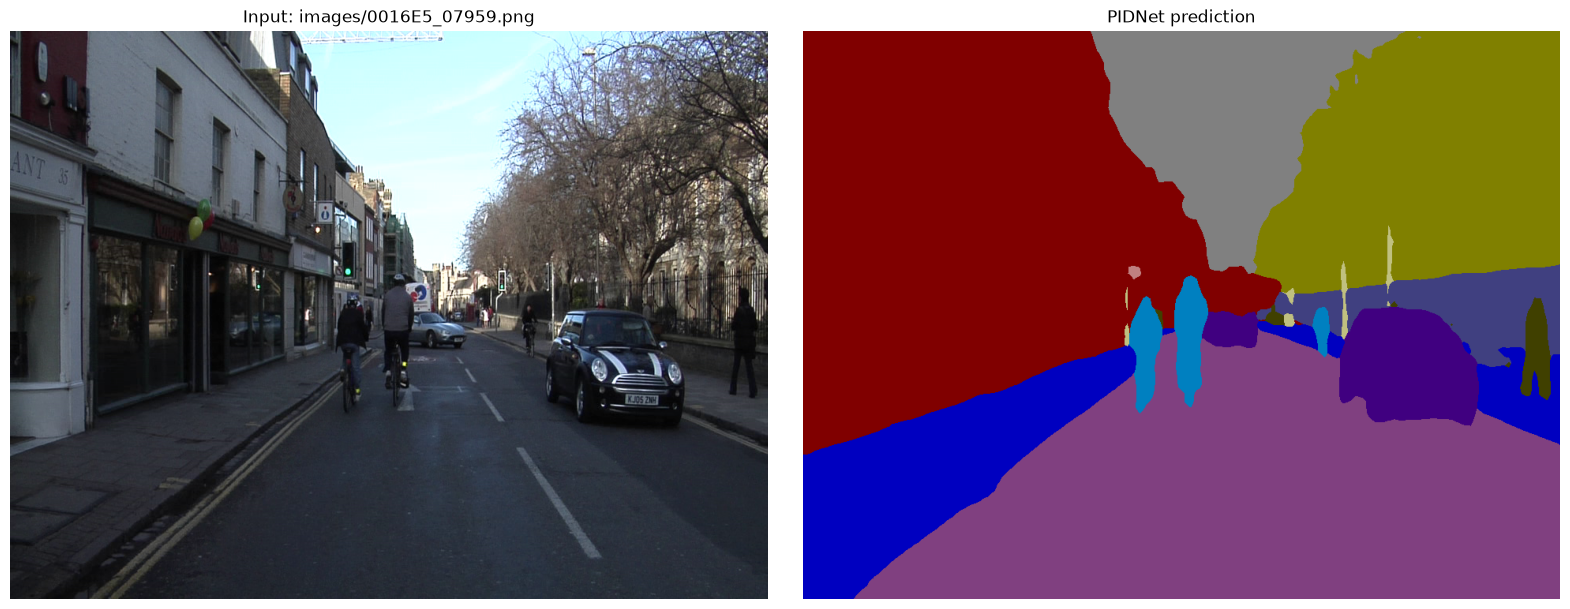

In [104]:
# Visualize one CamVid prediction from the saved notebook checkpoint.
!pip install matplotlib
import matplotlib.pyplot as plt

checkpoint_path = os.path.join(config.OUTPUT_DIR, 'best.pt')
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
checkpoint_state = checkpoint.get('state_dict', checkpoint)

inference_model = model.module if isinstance(model, nn.DataParallel) else model
if isinstance(inference_model, FullModel):
    inference_model = inference_model.model

model_state = inference_model.state_dict()
compatible_state = {}
for key, value in checkpoint_state.items():
    if key.startswith('module.'):
        key = key[7:]
    if key.startswith('model.'):
        key = key[6:]
    if key in model_state and value.shape == model_state[key].shape:
        compatible_state[key] = value

inference_model.load_state_dict(compatible_state, strict=False)
inference_model.eval()

list_path = os.path.join(
    config.DATASET.ROOT,
    config.DATASET.TEST_SET.lstrip('/')
)
with open(list_path) as file:
    image_name = file.readline().strip().split()[0]

image_path = os.path.join(config.DATASET.ROOT, 'camvid', image_name)
rgb_image = np.array(Image.open(image_path).convert('RGB'))
input_image = train_dataset.input_transform(rgb_image, city=False)
input_tensor = torch.from_numpy(input_image.transpose((2, 0, 1))).unsqueeze(0).float().to(device)

with torch.no_grad():
    prediction = inference_model(input_tensor)
    if isinstance(prediction, (list, tuple)):
        prediction = prediction[config.TEST.OUTPUT_INDEX]
    prediction = F.interpolate(
        prediction,
        size=rgb_image.shape[:2],
        mode='bilinear',
        align_corners=config.MODEL.ALIGN_CORNERS
    )
    prediction = prediction.argmax(dim=1)[0].cpu().numpy()

prediction_rgb = test_dataset.label2color(prediction)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(rgb_image)
axes[0].set_title(f'Input: {image_name}')
axes[1].imshow(prediction_rgb)
axes[1].set_title('PIDNet prediction')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()

In [103]:
# Evaluate test-set IoU without changing the notebook validation configuration.
test_dataset_for_iou = CamVid(
    root=config.DATASET.ROOT,
    list_path='list/camvid/test.lst',
    num_classes=config.DATASET.NUM_CLASSES,
    multi_scale=False,
    flip=False,
    ignore_label=config.TRAIN.IGNORE_LABEL,
    base_size=config.TEST.BASE_SIZE,
    crop_size=(config.TEST.IMAGE_SIZE[1], config.TEST.IMAGE_SIZE[0])
)

test_loader_for_iou = torch.utils.data.DataLoader(
    test_dataset_for_iou,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=use_cuda and config.PIN_MEMORY
)

num_classes = config.DATASET.NUM_CLASSES
ignore_label = config.TRAIN.IGNORE_LABEL

confusion_matrix = np.zeros((num_classes, num_classes), dtype=np.float64)

inference_model.eval()
with torch.no_grad():
    for images, labels, _, sizes, _ in test_loader_for_iou:
        images = images.to(device, non_blocking=use_cuda)
        predictions = inference_model(images)
        if isinstance(predictions, (list, tuple)):
            predictions = predictions[config.TEST.OUTPUT_INDEX]
        predictions = F.interpolate(
            predictions,
            size=labels.shape[-2:],
            mode='bilinear',
            align_corners=config.MODEL.ALIGN_CORNERS
        )

        # Per-pixel class prediction and ground truth, flattened
        pred_labels = torch.argmax(predictions, dim=1).cpu().numpy().astype(np.int64).flatten()
        gt_labels = labels.cpu().numpy().astype(np.int64).flatten()

        # Drop ignored pixels and any out-of-range labels
        valid = (gt_labels != ignore_label) & (gt_labels >= 0) & (gt_labels < num_classes)
        gt_valid = gt_labels[valid]
        pred_valid = pred_labels[valid]

        # Accumulate confusion matrix: rows = ground truth, cols = prediction
        index = gt_valid * num_classes + pred_valid
        confusion_matrix += np.bincount(
            index, minlength=num_classes ** 2
        ).reshape(num_classes, num_classes)

# IoU = TP / (TP + FP + FN), computed per class
tp = np.diag(confusion_matrix)
fp = confusion_matrix.sum(axis=0) - tp
fn = confusion_matrix.sum(axis=1) - tp
denominator = tp + fp + fn

iou_per_class = np.divide(
    tp, denominator,
    out=np.full_like(tp, np.nan),
    where=denominator > 0
)
mean_iou = np.nanmean(iou_per_class)
pixel_accuracy = tp.sum() / confusion_matrix.sum()

print(f"Test mIoU: {mean_iou:.4f}")
print(f"Test pixel accuracy: {pixel_accuracy:.4f}")
for class_idx, class_iou in enumerate(iou_per_class):
    print(f"  Class {class_idx:2d} IoU: {class_iou:.4f}")

Test mIoU: 0.7158
Test pixel accuracy: 0.9351
  Class  0 IoU: 0.6508
  Class  1 IoU: 0.8750
  Class  2 IoU: 0.9199
  Class  3 IoU: 0.3540
  Class  4 IoU: 0.4750
  Class  5 IoU: 0.6340
  Class  6 IoU: 0.9578
  Class  7 IoU: 0.8820
  Class  8 IoU: 0.4210
  Class  9 IoU: 0.9249
  Class 10 IoU: 0.7790
